**Activity 2**: Simple House Price Prediction

**Course**: Machine Learning

**Roll No**- AD3270

Dataset source: https://www.kaggle.com/datasets/shashanknecrothapa/ames-housing-dataset


 1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

2. Upload and Load Dataset

In [ ]:
df = pd.read_csv("AmesHousing.csv")

print("Dataset loaded: AmesHousing.csv")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded: AmesHousing.csv
Dataset shape: (2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


3. Inspect the Dataset

In [ ]:
display(df.head())
display(df.tail())

print("Number of rows and columns:", df.shape)
print("Column names:")
print(df.columns.tolist())

print("Dataset information:")
df.info()

print("Statistical summary:")
display(df.describe(include="all"))

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
2925,2926,923275080,80,RL,37.0,7937,Pave,NaN,IR1,Lvl,...,0,NaN,GdPrv,NaN,0,3,2006,WD,Normal,142500
2926,2927,923276100,20,RL,NaN,8885,Pave,NaN,IR1,Low,...,0,NaN,MnPrv,NaN,0,6,2006,WD,Normal,131000
2927,2928,923400125,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,132000
2928,2929,924100070,20,RL,77.0,10010,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2006,WD,Normal,170000
2929,2930,924151050,60,RL,74.0,9627,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,11,2006,WD,Normal,188000


Number of rows and columns: (2930, 82)
Column names:
['Order', 'PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air', 'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual', 'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu', 'Garage Type', 'Garage Yr Blt', 'Garage Finish', 'Garage Cars', 'Garage Area', 'Ga

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
count,2930.00000,2.930000e+03,2930.000000,2930,2440.000000,2930.000000,2930,198,2930,2930,...,2930.000000,13,572,106,2930.000000,2930.000000,2930.000000,2930,2930,2930.000000
unique,NaN,NaN,NaN,7,NaN,NaN,2,2,4,4,...,NaN,4,4,5,NaN,NaN,NaN,10,6,NaN
top,NaN,NaN,NaN,RL,NaN,NaN,Pave,Grvl,Reg,Lvl,...,NaN,Ex,MnPrv,Shed,NaN,NaN,NaN,WD,Normal,NaN
freq,NaN,NaN,NaN,2273,NaN,NaN,2918,120,1859,2633,...,NaN,4,330,95,NaN,NaN,NaN,2536,2413,NaN
mean,1465.50000,7.144645e+08,57.387372,NaN,69.224590,10147.921843,NaN,NaN,NaN,NaN,...,2.243345,NaN,NaN,NaN,50.635154,6.216041,2007.790444,NaN,NaN,180796.060068
std,845.96247,1.887308e+08,42.638025,NaN,23.365335,7880.017759,NaN,NaN,NaN,NaN,...,35.597181,NaN,NaN,NaN,566.344288,2.714492,1.316613,NaN,NaN,79886.692357
min,1.00000,5.263011e+08,20.000000,NaN,21.000000,1300.000000,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,1.000000,2006.000000,NaN,NaN,12789.000000
25%,733.25000,5.284770e+08,20.000000,NaN,58.000000,7440.250000,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,4.000000,2007.000000,NaN,NaN,129500.000000
50%,1465.50000,5.354536e+08,50.000000,NaN,68.000000,9436.500000,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,6.000000,2008.000000,NaN,NaN,160000.000000
75%,2197.75000,9.071811e+08,70.000000,NaN,80.000000,11555.250000,NaN,NaN,NaN,NaN,...,0.000000,NaN,NaN,NaN,0.000000,8.000000,2009.000000,NaN,NaN,213500.000000


## 4. Identify Missing Values

In [ ]:
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percent
})

display(missing_summary[missing_summary["Missing Values"] > 0].sort_values(
    by="Missing Values", ascending=False
))

print("Total missing values:", df.isnull().sum().sum())

,Missing Values,Missing Percentage
Pool QC,2917,99.556314
Misc Feature,2824,96.382253
Alley,2732,93.242321
Fence,2358,80.477816
Mas Vnr Type,1775,60.580205
Fireplace Qu,1422,48.532423
Lot Frontage,490,16.723549
Garage Qual,159,5.426621
Garage Cond,159,5.426621
Garage Yr Blt,159,5.426621


Total missing values: 15749


## 5. Check Duplicate Records

In [ ]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

if duplicate_count > 0:
    df = df.drop_duplicates().copy()

print("Shape after duplicate check:", df.shape)

Number of duplicate rows: 0
Shape after duplicate check: (2930, 82)


## 6. Handle Missing Values and Prepare Data

In [ ]:
cleaned_df = df.copy()

numeric_columns = cleaned_df.select_dtypes(include=np.number).columns
categorical_columns = cleaned_df.select_dtypes(include=["object", "category"]).columns

for column in numeric_columns:
    cleaned_df[column] = cleaned_df[column].fillna(cleaned_df[column].median())

for column in categorical_columns:
    mode_value = cleaned_df[column].mode()
    if not mode_value.empty:
        cleaned_df[column] = cleaned_df[column].fillna(mode_value[0])

print("Total missing values after cleaning:", cleaned_df.isnull().sum().sum())
print("Duplicate rows after cleaning:", cleaned_df.duplicated().sum())
print("Cleaned dataset shape:", cleaned_df.shape)

Total missing values after cleaning: 0
Duplicate rows after cleaning: 0
Cleaned dataset shape: (2930, 82)


## 7. Select Input Feature and Target

In [ ]:
X = cleaned_df[["Gr Liv Area"]]
y = cleaned_df["SalePrice"]

print("Input feature:", X.columns.tolist())
print("Target variable:", y.name)
print("Input shape:", X.shape)
print("Target shape:", y.shape)

display(pd.concat([X, y], axis=1).head())

Input feature: ['Gr Liv Area']
Target variable: SalePrice
Input shape: (2930, 1)
Target shape: (2930,)


,Gr Liv Area,SalePrice
0,1656,215000
1,896,105000
2,1329,172000
3,2110,244000
4,1629,189900


## 8. Visualize the Relationship

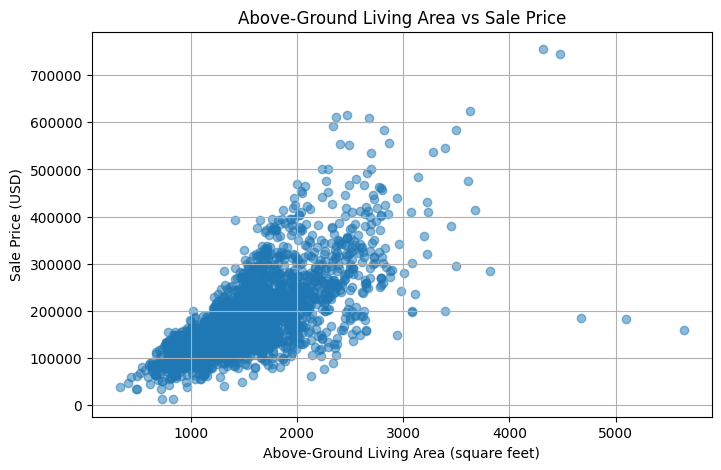

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(X["Gr Liv Area"], y, alpha=0.5)
plt.title("Above-Ground Living Area vs Sale Price")
plt.xlabel("Above-Ground Living Area (square feet)")
plt.ylabel("Sale Price (USD)")
plt.grid(True)
plt.show()

## 9. Split Data into Training and Testing Sets

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Total observations:", len(cleaned_df))
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

Total observations: 2930
Training observations: 2344
Testing observations: 586


## 10. Train the Linear Regression Model

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])
print(f"SalePrice = {model.intercept_:.2f} + ({model.coef_[0]:.2f} × Gr Liv Area)")

Intercept: 19250.559555372573
Coefficient: 106.72915508271505
SalePrice = 19250.56 + (106.73 × Gr Liv Area)


## 11. Generate Predictions

In [ ]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Sale Price": y_test.values,
    "Predicted Sale Price": y_pred
})

display(comparison.head(10))

,Actual Sale Price,Predicted Sale Price
0,161000,197061.331923
1,116000,129181.589291
2,196500,203251.622918
3,123600,124912.423087
4,126000,117334.653076
5,174190,160773.419195
6,200000,128114.297740
7,148500,174648.209356
8,88750,94387.884734
9,409900,288208.030364


## 12. Evaluate the Model

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R²): {r2:.4f}")

Mean Absolute Error (MAE): 41365.51
Mean Squared Error (MSE): 3821184066.27
Root Mean Squared Error (RMSE): 61815.73
R-squared (R²): 0.5234


## 13. Visualize Actual vs Predicted Prices

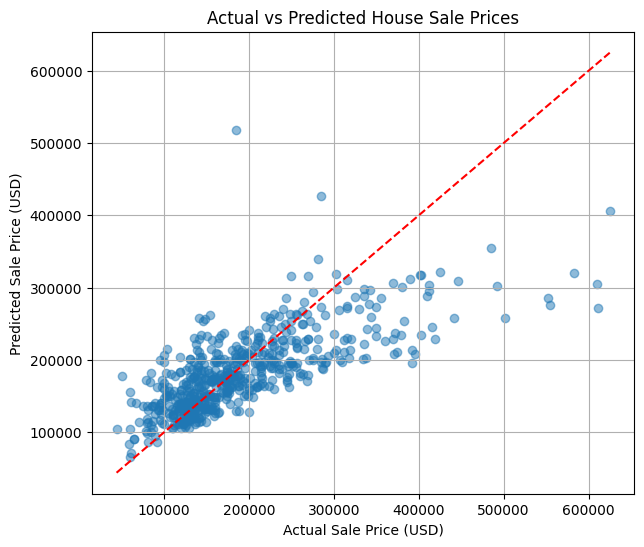

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.5)

lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot([lower, upper], [lower, upper], "r--")
plt.title("Actual vs Predicted House Sale Prices")
plt.xlabel("Actual Sale Price (USD)")
plt.ylabel("Predicted Sale Price (USD)")
plt.grid(True)
plt.show()

## 14. Predict the Price of a New House

In [ ]:
new_house = pd.DataFrame({"Gr Liv Area": [1500]})
new_prediction = model.predict(new_house)

print("Above-ground living area:", new_house.loc[0, "Gr Liv Area"], "square feet")
print("Predicted sale price (USD):", round(new_prediction[0], 2))

Above-ground living area: 1500 square feet
Predicted sale price (USD): 179344.29


## 15. Save the Cleaned Dataset

In [ ]:
cleaned_df.to_csv("AmesHousing_Cleaned.csv", index=False)

print("Cleaned dataset saved as AmesHousing_Cleaned.csv")
print("Final cleaned dataset shape:", cleaned_df.shape)

Cleaned dataset saved as AmesHousing_Cleaned.csv
Final cleaned dataset shape: (2930, 82)


## 16. Conclusion

A Linear Regression model was developed using the Ames Housing dataset to predict house sale prices. The `Gr Liv Area` feature was selected as the input and `SalePrice` as the target. The dataset was inspected for missing values and duplicate records. Missing numerical values were filled using median values, and missing categorical values were filled using mode values. Duplicate rows were checked and removed if present. The data was divided into training and testing sets in an 80:20 ratio. The model was trained and evaluated using MAE, MSE, RMSE and R-squared. A new house price prediction was also generated.

The model uses only one input feature. Actual house prices may also depend on location, quality, age, number of rooms and other factors. Therefore, the prediction is an estimate and may not represent the exact market price.